### Imports

In [58]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, mean_squared_error
from sklearn.preprocessing import PolynomialFeatures

from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LassoCV
from sklearn.pipeline import make_pipeline

from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    mean_squared_error,
    r2_score,
    mean_absolute_error
)


import seaborn as sns

### Data read and add krpm

In [59]:
data_train = pd.read_csv('data/case1/train1.csv')
data_test = pd.read_csv('data/case1/test1.csv')

data_train['speed_krpm'] = data_train.speed_rpm / 1000
data_train['delta_p'] = data_train.outlet_pressure_bar - data_train.inlet_pressure_bar

data_test['speed_krpm'] = data_test.speed_rpm / 1000
data_test['delta_p'] = data_test.outlet_pressure_bar - data_test.inlet_pressure_bar


data_train.head()
print(len(data_train))
print(len(data_test))
print(data_train.columns)

480
120
Index(['pump_id', 'elapsed_s', 'operating_state', 'speed_rpm', 'power_w',
       'inlet_pressure_bar', 'outlet_pressure_bar', 'flow_m3_h', 'speed_krpm',
       'delta_p'],
      dtype='object')


# Data Cleaning

In [60]:
# Check for NaN
print(f"Missing values inside train: {data_train.isna().sum().sum()}")
print(f"Missing values inside test: {data_train.isna().sum().sum()}")


print(f"Duplicated rows in train: {data_train.duplicated().sum()}")
print(f"Duplicated rows in test: {data_train.duplicated().sum()}")

print()
print("Description of Flow (target)")
print(data_train.flow_m3_h.describe())

print()
print("Description of speed (predictor)")
print(data_train.speed_krpm.describe())

print()
print("Description of power (predictor)")
print(data_train.power_w.describe())

print()
print("Description of delta_p (predictor)")
print(data_train.delta_p.describe())


##### No missing values, no obvious outliers or illogical values


Missing values inside train: 0
Missing values inside test: 0
Duplicated rows in train: 0
Duplicated rows in test: 0

Description of Flow (target)
count    480.000000
mean      18.792311
std       13.066647
min        0.354386
25%        7.979561
50%       16.522224
75%       27.438485
max       56.823209
Name: flow_m3_h, dtype: float64

Description of speed (predictor)
count    480.000000
mean       3.167585
std        0.993327
min        1.494159
25%        2.358835
50%        3.221082
75%        4.073169
max        4.813199
Name: speed_krpm, dtype: float64

Description of power (predictor)
count     480.000000
mean      703.518374
std       553.346321
min        63.185204
25%       227.256230
50%       551.359686
75%      1042.022701
max      2201.655665
Name: power_w, dtype: float64

Description of delta_p (predictor)
count    480.000000
mean       0.667123
std        0.444220
min        0.039170
25%        0.282000
50%        0.563840
75%        0.969504
max        1.764468
Name: d

# Plotting

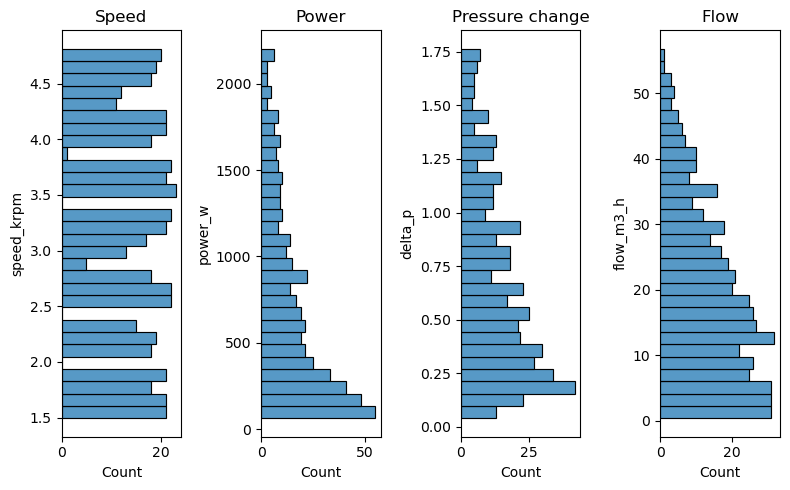

In [61]:
fig, axes = plt.subplots(1, 4, figsize=(8, 5))

sns.histplot(
    y='speed_krpm',
    data=data_train,
    ax=axes[0],
    bins = 30
)
axes[0].set_title("Speed")

sns.histplot(
    y='power_w',
    data=data_train,
    ax=axes[1],
    bins = 30

)
axes[1].set_title("Power")

sns.histplot(
    y='delta_p',
    data=data_train,
    ax=axes[2],
    bins = 30

)
axes[2].set_title("Pressure change")

sns.histplot(
    y='flow_m3_h',
    data=data_train,
    ax=axes[3],
    bins = 30

)
axes[3].set_title("Flow")

plt.tight_layout()
plt.show()

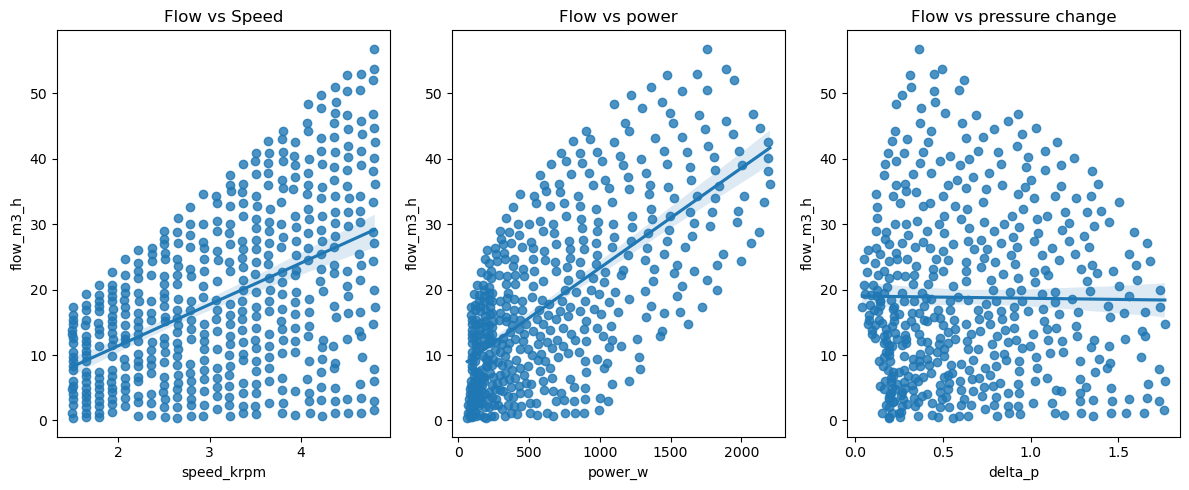

In [62]:
# Plots of target vs predictors
fig, axes = plt.subplots(1, 3, 
                         figsize=(12, 5),
                         sharex=False, sharey=False
                         )

sns.regplot(
    x='speed_krpm',
    y='flow_m3_h',
    data=data_train,
    ax=axes[0],
)
axes[0].set_title("Flow vs Speed")

sns.regplot(
    x='power_w',
    y='flow_m3_h',
    data=data_train,
    ax=axes[1],

)
axes[1].set_title("Flow vs power")

sns.regplot(
    x='delta_p',
    y='flow_m3_h',
    data=data_train,
    ax=axes[2],

)
axes[2].set_title("Flow vs pressure change")



plt.tight_layout()
plt.show()

# Correlation Matrix

            flow_m3_h  speed_krpm   power_w   delta_p
flow_m3_h    1.000000    0.480322  0.646600 -0.011799
speed_krpm   0.480322    1.000000  0.913282  0.836032
power_w      0.646600    0.913282  1.000000  0.717465
delta_p     -0.011799    0.836032  0.717465  1.000000


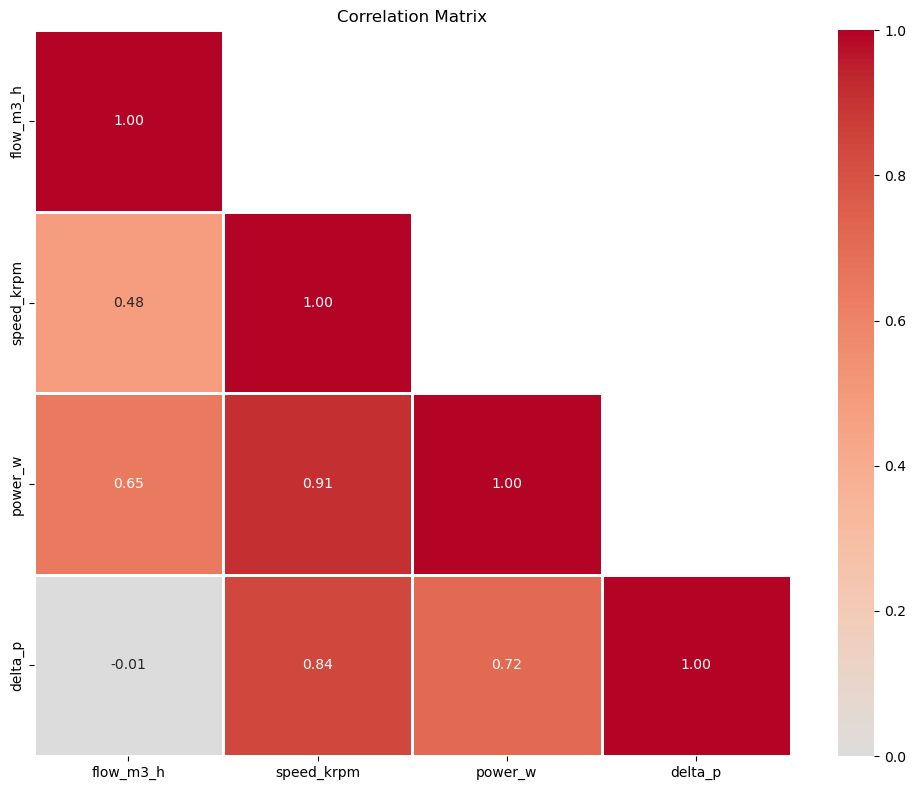

In [63]:
corr_matrix = data_train[['flow_m3_h','speed_krpm','power_w','delta_p']].corr(numeric_only=True)
print(corr_matrix)
#Hide upper triangle
mask = np.triu(np.ones_like(corr_matrix, dtype=bool), k = 1)

plt.figure(figsize=(10, 8))

sns.heatmap(
    corr_matrix,
    mask =mask,
    annot=True,         
    cmap='coolwarm',    
    fmt='.2f',           
    linewidths=1,
    vmin=0,
    vmax=1,
    center=0
)

plt.title("Correlation Matrix")
plt.tight_layout()
plt.show()




 We can see that power shows most correlation with flow. delta_p - no correlation on its own. there is also multicollinearity, as speed and power are highly correlated, and speed and delta p are also highly correlated


# Basic Model

In [64]:
### First, I want to generate all possible combinations of the delta_p, speed_krpm, power_w

# original ones
X_train = data_train[['speed_krpm','power_w','delta_p']]
y_train = data_train['flow_m3_h']

X_test = data_test[['speed_krpm','power_w','delta_p']]
y_test = data_test['flow_m3_h']



# Train a basic linear model with the initial 3 features

In [65]:
lr_simple = LinearRegression()
lr_simple.fit(X_train, y_train)
coefficients = pd.DataFrame({
    'Feature': X_train.columns,
    'Coefficient': lr_simple.coef_
})

print(coefficients)

print("Intercept:", lr_simple.intercept_)


#### Metrics

simple_y_pred = lr_simple.predict(X_train)

print("\nTRAIN PERFORMANCE")
print("R2:", r2_score(y_train, simple_y_pred))
print("RMSE:", np.sqrt(mean_squared_error(y_train, simple_y_pred)))
print("MAE:", mean_absolute_error(y_train, simple_y_pred))

      Feature  Coefficient
0  speed_krpm     8.945708
1     power_w     0.021504
2     delta_p   -36.289633
Intercept: -0.46309489895181244

TRAIN PERFORMANCE
R2: 0.9300401503511506
RMSE: 3.4525161914684577
MAE: 2.842230377341141


### spme plots

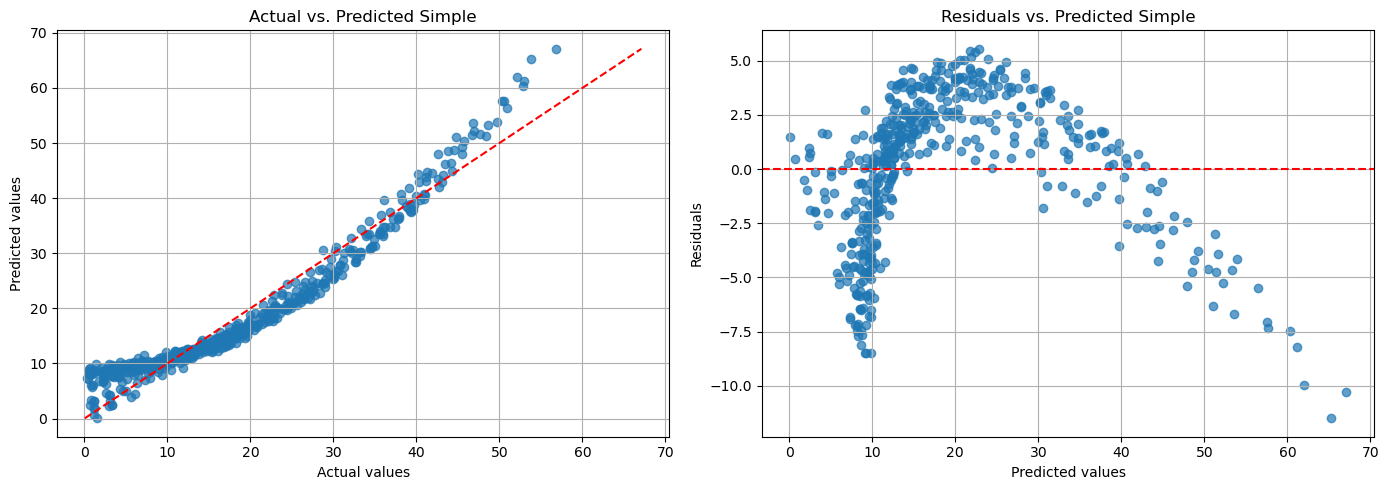

In [66]:

# Calculate residuals
residuals = y_train - simple_y_pred

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Actual vs Predicted
axes[0].scatter(y_train, simple_y_pred, alpha=0.7)

# Perfect prediction line
min_val = min(y_train.min(), simple_y_pred.min())
max_val = max(y_train.max(), simple_y_pred.max())
axes[0].plot([min_val, max_val], [min_val, max_val], 'r--') ##### the diagonal red line

axes[0].set_xlabel("Actual values")
axes[0].set_ylabel("Predicted values")
axes[0].set_title("Actual vs. Predicted Simple")
axes[0].grid(True)

# Plot 2: Residuals vs Predicted
axes[1].scatter(simple_y_pred, residuals, alpha=0.7)
axes[1].axhline(y=0, color='r', linestyle='--')

axes[1].set_xlabel("Predicted values")
axes[1].set_ylabel("Residuals")
axes[1].set_title("Residuals vs. Predicted Simple")
axes[1].grid(True)

plt.tight_layout()
plt.show()

#### As it can be seen from the plots, the relationship is not linear, as the errors are not homoscedastic.
We should try interactions

# feature engineering

In [ ]:


from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.linear_model import LassoCV, LinearRegression
from sklearn.pipeline import make_pipeline


# FEATURE ENGINEERING

poly = PolynomialFeatures(
    degree=3,
    include_bias=False
)

X_train_pol = pd.DataFrame(
    poly.fit_transform(X_train),
    columns=poly.get_feature_names_out(X_train.columns),
    index=X_train.index
)

X_test_pol = pd.DataFrame(
    poly.transform(X_test),
    columns=poly.get_feature_names_out(X_test.columns),
    index=X_test.index
)


# LASSO FEATURE SELECTION

lasso_model = make_pipeline(
    StandardScaler(),
    LassoCV(
        cv=5,
        max_iter=40000,
        random_state=42
    )
)

# Fit Lasso ONLY on training data
lasso_model.fit(X_train_pol, y_train)

lasso = lasso_model.named_steps['lassocv']

# Identify selected features
selected_features = X_train_pol.columns[lasso.coef_ != 0]

print("Selected features:")
print(selected_features.tolist())

print("Number of selected features:",
      len(selected_features))

print("Optimal alpha:", lasso.alpha_)


# SELECT FEATURES

X_train_selected = X_train_pol[selected_features]
X_test_selected = X_test_pol[selected_features]


# LINEAR REGRESSION

lr_pol = LinearRegression()

# Fit Linear Regression on selected training features
lr_pol.fit(X_train_selected, y_train)


#  PREDICTIONS

y_train_pred_pol = lr_pol.predict(X_train_selected)


# EVALUATION

print("\nTRAIN PERFORMANCE")
print("R2:", r2_score(y_train, y_train_pred_pol))
print("RMSE:", np.sqrt(mean_squared_error(y_train, y_train_pred_pol)))
print("MAE:", mean_absolute_error(y_train, y_train_pred_pol))


# FINAL REGRESSION COEFFICIENTS

coefficients = pd.DataFrame({
    'Feature': selected_features,
    'Coefficient': lr_pol.coef_
})

print("\nFINAL LINEAR REGRESSION COEFFICIENTS")
print(coefficients)

print("Intercept:", lr_pol.intercept_)

Selected features:
['speed_krpm', 'power_w', 'delta_p', 'power_w^2', 'delta_p^2', 'speed_krpm^3', 'speed_krpm^2 power_w', 'speed_krpm^2 delta_p', 'speed_krpm delta_p^2', 'power_w^3', 'power_w^2 delta_p']
Number of selected features: 11
Optimal alpha: 0.008440086132555867

TRAIN PERFORMANCE
R2: 0.9892378260685007
RMSE: 1.3541329115653256
MAE: 1.003491741606244

FINAL LINEAR REGRESSION COEFFICIENTS
                 Feature   Coefficient
0             speed_krpm  1.413797e+01
1                power_w  7.700348e-02
2                delta_p -7.690051e+01
3              power_w^2 -2.040819e-05
4              delta_p^2  2.281743e+01
5           speed_krpm^3 -7.724243e-01
6   speed_krpm^2 power_w -5.227691e-04
7   speed_krpm^2 delta_p  1.976377e+00
8   speed_krpm delta_p^2 -1.809331e+00
9              power_w^3  8.378302e-09
10     power_w^2 delta_p -8.154446e-06
Intercept: -6.888338798183121


## and some plots for the regression with polynomial features and lasso regularization

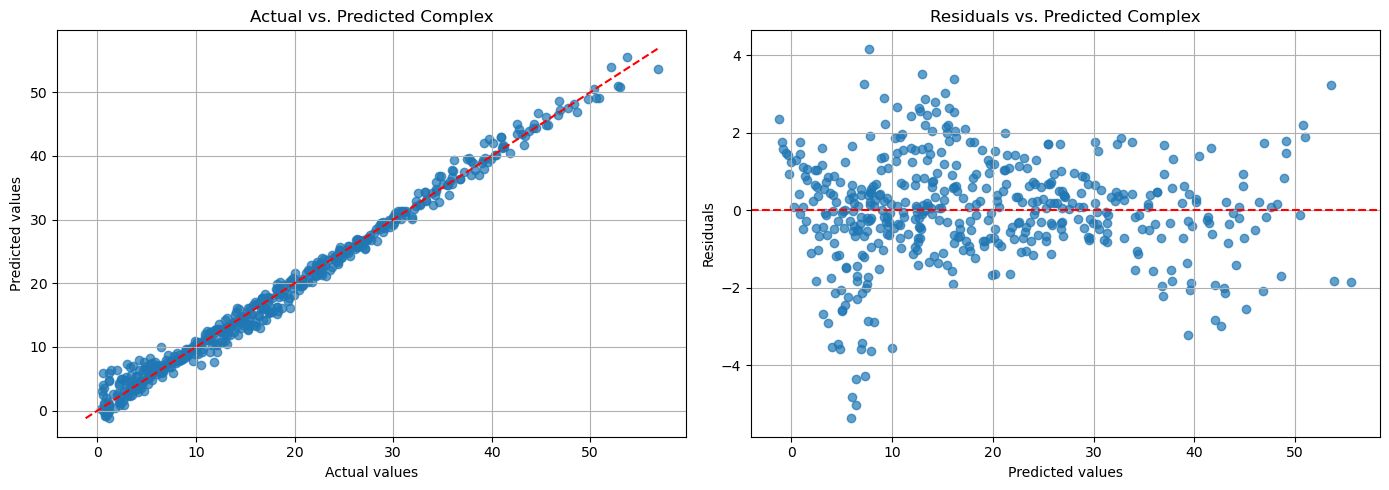

In [68]:
# Calculate residuals
residuals = y_train - y_train_pred_pol

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Actual vs Predicted
axes[0].scatter(y_train, y_train_pred_pol, alpha=0.7)

# Perfect prediction line
min_val = min(y_train.min(), y_train_pred_pol.min())
max_val = max(y_train.max(), y_train_pred_pol.max())
axes[0].plot([min_val, max_val], [min_val, max_val], 'r--') ##### the diagonal red line

axes[0].set_xlabel("Actual values")
axes[0].set_ylabel("Predicted values")
axes[0].set_title("Actual vs. Predicted Complex")
axes[0].grid(True)

# Plot 2: Residuals vs Predicted
axes[1].scatter(y_train_pred_pol, residuals, alpha=0.7)
axes[1].axhline(y=0, color='r', linestyle='--')

axes[1].set_xlabel("Predicted values")
axes[1].set_ylabel("Residuals")
axes[1].set_title("Residuals vs. Predicted Complex")
axes[1].grid(True)

plt.tight_layout()
plt.show()

# Testing the baseline and the engineered model

In [69]:
y_test_pred_simple = lr_simple.predict(X_test)
y_test_pred_pol = lr_pol.predict(X_test_selected)


print("\nTEST PERFORMANCE SIMPLE")
print("R2:", r2_score(y_test, y_test_pred_simple))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_test_pred_simple)))
print("MAE:", mean_absolute_error(y_test, y_test_pred_simple))



print("\nTEST PERFORMANCE COMPLEX")
print("R2:", r2_score(y_test, y_test_pred_pol))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_test_pred_pol)))
print("MAE:", mean_absolute_error(y_test, y_test_pred_pol))



TEST PERFORMANCE SIMPLE
R2: 0.9141984630856215
RMSE: 3.5362865109259634
MAE: 2.926193436866453

TEST PERFORMANCE COMPLEX
R2: 0.9892961981028452
RMSE: 1.2490187046333872
MAE: 0.906726188650268
